[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/hbprosper/mlinphysics/blob/main/Labs/05.PINN/tutorial_PINN_SIR_y.ipynb)

# Physics Informed Neural Networks (PINN): SIR Model, $y = \ln I$
> For the Fall 2026 course: *Machine Learning in Physics*<br>
> Created: Oct. 18, 2026 Harrison B. Prosper<br>

## Introduction
Notebook `tutorial_PINN` introduced the method of **physics-informed neural networks**[1, 2] (PINN) for solving differential equations using the damped harmonic oscillator as an example. To illustrate why PINN is a misnomer, in this tutorial we consider the well-studied **S**usceptible, **I**nfectious, **R**ecovered (SIR) epidemiological model [3] defined by the coupled ordinary differential equations

\begin{align}
    \frac{dS}{dt} & = - \frac{\beta}{N} S I,\quad
    \frac{dI}{dt}  = + \frac{\beta}{N} S I - \gamma I ,\quad
    \frac{dR}{dt}  = \gamma I,
\end{align}
where $S$, $I$, and $R$ are mean counts of susceptible, infectious, or recovered individuals, respectively, which (in this version of the model) satisfy the constraint $S + I + R = N$ and $N$ is the *fixed* population size. The SIR model, illustrated below, describes, on average, the flow of individuals between the three **compartments**.

<img src="./SIR.png" width="600"/>

Instead of absolute mean counts, following [3], let's reinterpret $S$, $I$, $R$ as *fractions* of the population through the replacements $S \rightarrow N S$, $I \rightarrow N I$, and $R \rightarrow N R$,
\begin{align}
    N\frac{dS}{dt} & = - N^2 \frac{\beta}{N} S I,\quad
    N\frac{dI}{dt}  = + N^2 \frac{\beta}{N} S I - N \gamma I ,\quad
    N\frac{dR}{dt}  = N \gamma I, \\
    \frac{dS}{dt} & = - \beta S I,\quad
    \frac{dI}{dt}  = + \beta S I - \gamma I ,\quad
    \frac{dR}{dt}  = \gamma I .
\end{align}
Furthermore, again following [3], the replacement $t \rightarrow \gamma t$ yields
\begin{align}
    \frac{dS}{dt} & = - R_0  S I,\quad
    \frac{dI}{dt}  = (R_0 S - 1) I ,\quad
    \frac{dR}{dt}  = I ,
\end{align}
where the **reproduction number** $R_0 = \beta / \gamma$ (not to be confused with R(t=0)!) determines whether infections quickly subside or an epidemic unfolds. Consider the equation $dI / dt =  (R_0 S - 1) I$. Notice that the average number of infections subsides when $R_0 S < 1$ and increases when $R_0 S > 1$.

Hereafter, it is understood that $t$ is dimensionless and $S$, $I$, and $R$ are fractions that satisfy $S + I + R = 1$.

In this notebook we apply the PINN method to solve the differential equation for $y(t) = \ln I(t)$.

### References
  1. B. Moseley, see, for example, https://www.youtube.com/watch?v=IDIv92Z6Qvc; B. Moseley, Deep Learning in Scientific Computing (2023), ETH Zürich, Computational and Applied Mathematics Laboratory (CAMLab).
  2. S. Cuomo et al., *Scientific Machine Learning through Physics-Informed Neural Networks: Where we are and What's next*, https://doi.org/10.48550/arXiv.2201.05624.
  3. LibreTexts: [SIR Model](https://math.libretexts.org/Bookshelves/Applied_Mathematics/Mathematical_Biology_(Chasnov)/04%3A_Infectious_Disease_Modeling/4.03%3A_The_SIR_Epidemic_Disease_Model)
  4. D. Mortari, The Theory of Connections: Connecting Points, Mathematics, vol. 5, no. 57, 2017.

## Exercises

### 1. Show that
\begin{align}
    \frac{dS}{dt} & = - R_0  S I,\quad
    \frac{dI}{dt}  = (R_0 S - 1) I,
\end{align}
can be expressed as
\begin{align}
    \dot{x} & = -R_0 \exp(y),\\
    \dot{y} & = + R_0 \exp(x) - 1,
\end{align}
where $x = \ln S$, $y = \ln I$ and the overdot denotes differentiation with respect to $t$. 

*Hint*: $S^{-1} dS /dt = d\ln S / dt$ etc.

### 2. Show that $x$ and $y$ satisfy the 2nd-order ODEs
\begin{align}
    \ddot{x} & = \dot{x} \, (R_0 \exp(x) - 1) , \\
    \ddot{y} & =-R_0 \exp(y) \, (\dot{y} + 1).
\end{align}


### 3. Use a PINN to solve the ODE for $y$

**Initial conditions**
\begin{align}
    y(0) & = \ln I_0,\\
    \dot{y}(0) & = R_0 S_0 - 1.
\end{align}

**Domain**
\begin{align}
    t & \in [0, 1], \\ 
    I_0 & \in [0.001, 0.1], & \text{ (initial fraction of infected individuals)},\\ 
    R_0 & \in [0.5, 5], & \text{ (reproduction numbers)}.
\end{align}

## Running on Google Colab
If on Google Colab (https://colab.research.google.com), execute cell below.

In [2]:
try:
    import google.colab
    
    REPO = 'hbprosper/mlinphysics'
    
    url = f"https://raw.githubusercontent.com/{REPO}/refs/heads/main"
    !wget -q {url}/clone2colab.ipynb -O clone2colab.ipynb
    %run clone2colab.ipynb
    
    IN_COLAB = True

except ImportError:
    
    IN_COLAB = False

In [3]:
# standard system modules
import os, sys, copy

# standard module for tabular data
import pandas as pd

# standard module for array manipulation
import numpy as np

# standard module for high-quality plots
import matplotlib as mp
import matplotlib.pyplot as plt

# standard research-level machine learning toolkit from Meta (FKA: FaceBook)
import torch
import torch.nn as nn
import torch.nn.init as init

from scipy.integrate import solve_ivp

# to reload modules
import importlib

# ML in physics module
import drwho.nn as mlp
import drwho.data as dat
import drwho.monitor as mon

# module for shell utilities
import shutil

plt.rcParams.update({
      "text.usetex": shutil.which('latex') is not None,
      "font.family": "sans-serif",
      "font.size": 12
})

In [4]:
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'\n\tComputational device: {str(DEVICE):4s}\n')


	Computational device: cpu 



## Solution using `solve_ivp`

```python
solve_ivp(fun, t_span, y0, method='RK45', t_eval=None, 
    dense_output=False, events=None, vectorized=False, 
    args=None, **options)
```

\begin{align}
    \frac{dS}{dt} & = - R_0  S I,\quad
    \frac{dI}{dt}  = + R_0 S I - I ,\quad
    \frac{dR}{dt}  = I ,
\end{align}

In [5]:
class RK45Solution:
    
    def __init__(self, S0, I0, R_0):

        # initial conditions
        self.S0 = S0
        self.I0 = I0
        self.R0 = 1 - S0 - I0
        
        # reproduction number
        self.R_0 = R_0

    def fun__(self, t, u):
        S, I, R =  u
        return [-self.R_0 * S * I, self.R_0 * S * I - I, I]

    def __call__(self, t, rtol=1e-4, atol=1e-7):

        # initial conditions
        y0 = self.S0, self.I0, self.R0

        # domain
        t_span  = [t[0], t[-1]]
        
        self.results = solve_ivp(
            self.fun__, t_span, y0, method='RK45', 
            t_eval=t, rtol=rtol, atol=atol)
        
        return self.results.y[0], self.results.y[1], self.results.y[2]

    def plot(self, ymin=0, ymax=1, 
             filename='results.png', width=6, ftsize=14):
        
        S, I, R = self.results.y
        t = self.results.t
        xmin, xmax = t[0], t[-1]

        fgsize = (width, width*9/16)
        # create an empty figure
        fig = plt.figure(figsize=fgsize)
        
        ax  = fig.add_subplot(1, 1, 1)
            
        ax.set_xlim(xmin, xmax)
        ax.set_xlabel(r'$t$', fontsize=ftsize)
        
        ax.set_ylabel(r'$S$, $I$, $R$', fontsize=ftsize)
        ax.set_ylim(ymin, ymax)
        
        ax.plot(
            t, S, color='blue', linestyle='solid', linewidth=1.0, label='S')
        
        ax.plot(
            t, I, color='red',  linestyle='solid', linewidth=1.0, label='I')
        
        ax.plot(
            t, R, color='green',linestyle='solid', linewidth=1.0, label='R')
        
        ax.legend()
        
        ax.grid()
        
        fig.tight_layout()
        plt.savefig(filename)

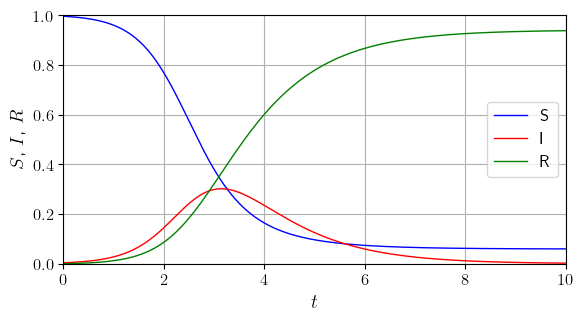

In [6]:
N  = 766
I0 = 3 / N
S0 = 1 - I0
R0 = 0

R_0= 3.0  # reproduction number

tmin, tmax = 0, 10
soln = RK45Solution(S0, I0, R_0)
t = np.linspace(tmin, tmax, 201)

S, I, R = soln(t)

soln.plot()

## Configuration

In [8]:
dataset_size_exponent = 17
dataset_size = 2**dataset_size_exponent  # Sobol sample size
test_size    = 2**13                     # test sample size
val_size     = 2**11                     # validation sample size
batch_size   = 2**10                     # large batches keep a GPU busy (see note above)

# domain of PINN solution
# -----------------------------------------
tmin, tmax = 0.0, 1.0
I0_min, I0_max = 1e-3, 1e-1
R_0_min, R_0_max = 0.5, 5.0

# sampling bounds for (t, I0, R_0)
lower_bounds = [tmin, I0_min, R_0_min]
upper_bounds = [tmax, I0_max, R_0_max]

# the network inputs are (t, log10(I0), R_0), mapped to [-1, 1]
# using these bounds (whichever way I0 is sampled)
input_lo = [0.0,  float(np.log10(I0_min)), R_0_min]
input_hi = [tmax, float(np.log10(I0_max)), R_0_max]

# name of model
name = 'sir'
dirname = 'exercise'

# create new configuration
config = mlp.Config(name, dirname=dirname)

# training configuration
# -----------------------------------------
train_size = dataset_size - val_size

config('batch_size', batch_size)
config('train_size', train_size)           # set training sample size
config('test_size',  test_size)            # set test sample size
config('val_size',   val_size)             # set validation sample size

config('monitor_step',  100)  # set monitor training every "n" iterations
config('delete', True)        # delete losses file before training, if True
config('frac', 0.015)         # save model if average loss decreases by more
                              # than frac percent

# optimizer / scheduler configuration
# -----------------------------------------
# a step comprises a given number of iterations
config('n_iters_per_step', 20_000)
config('n_steps', 8)          # number of training steps
config('n_iterations', config('n_steps') * config('n_iters_per_step'))

config('base_lr', 4e-4)       # initial learning rate
config('gamma', 0.80)         # learning rate scale factor


print(f'\nSave configuration to file {config('file/config')}\n')
config.save()

print(config)


Save configuration to file runs/exercise/sir_config.yaml

name: sir
file:
  losses: runs/exercise/sir_losses.csv
  params: runs/exercise/sir_params.pth
  init_params: runs/exercise/sir_init_params.pth
  plots: runs/exercise/sir_plots.png
  config: runs/exercise/sir_config.yaml
batch_size: 1024
train_size: 129024
test_size: 8192
val_size: 2048
monitor_step: 100
delete: true
frac: 0.015
n_iters_per_step: 20000
n_steps: 8
n_iterations: 160000
base_lr: 0.0004
gamma: 0.8



## Train, validation, and test sets
There is some confusion in terminology regarding validation and test samples (or sets). We shall adhere to the defintions given here https://machinelearningmastery.com/difference-test-validation-datasets/):
   
  * __Training Dataset__: The sample of data used to fit the model.
  * __Validation Dataset__: The sample of data used to decide 1) whether the fit is reasonable (e.g., the model has not been overfitted), 2) decide which of several models is the best and 3) tune model hyperparameters.
  * __Test Dataset__: The sample of data used to provide an unbiased evaluation of the fitted model.

The validation set will be some small fraction of the training set and will be used to decide when to stop the training.

## Generate raw data
Generate a quasi-random set of points, $p$, in $S_t \otimes S \subset \mathbb{R}^3$. Quasi-random sampling disributes points more evenly than uniform random sampling by reducing the degree if random clumping that characterizes random sampling.

In [9]:
sobol_sample = dat.SobolSample(lower_bounds, upper_bounds,
                               num_points_exp=dataset_size_exponent)
print()

uniform_sample = dat.UniformSample(lower_bounds, upper_bounds,
                                   num_points=test_size)

print(f'I0 range: [{sobol_sample[:, 1].min():.2e}, {sobol_sample[:, 1].max():.2e}]')
print(f'fraction of points with I0 < 0.01: {(sobol_sample[:, 1] < 0.01).mean():.2f}')

sobol_sample.shape, uniform_sample.shape

SobolSample
  131072 Sobol points created in unit 3-cube.

UniformSample
  8192 uniformly sampled points created in unit 3-cube.
I0 range: [1.00e-03, 1.00e-01]
fraction of points with I0 < 0.01: 0.09


((131072, 3), (8192, 3))

## Package raw data into `Dataset`s

In [10]:
importlib.reload(dat)

train_size = config('train_size')
val_size   = config('val_size')
test_size  = config('test_size')

# training dataset (this defines the empirical risk to be minimized)
print('training data')
train_data = dat.Dataset(sobol_sample,
                         start=0,
                         end=train_size,
                         # split at: y = x[:, split_col:], x = x[:, :split_col]
                         split_col=1,  
                         requires_grad=True)

# a random subset of the training data to check for overtraining
# by comparing with the empirical risk from the validation set
print('training data for validation')
train_data_val = dat.Dataset(sobol_sample,
                             start=0,
                             end=train_size,
                             split_col=1,
                             requires_grad=True,
                             random_sample_size=val_size)


# validation dataset (for monitoring training)
print('validation data')
val_data = dat.Dataset(uniform_sample,
                       start=0,
                       end=val_size, 
                       split_col=1,
                       requires_grad=True)

# test dataset
print('test data')
test_data= dat.Dataset(uniform_sample,
                       start=val_size,
                       end=val_size + test_size,
                       split_col=1,
                       requires_grad=True)

training data
Dataset
  shape of x: torch.Size([129024, 1])
  shape of y: torch.Size([129024, 2])

training data for validation
Dataset
  shape of x: torch.Size([2048, 1])
  shape of y: torch.Size([2048, 2])

validation data
Dataset
  shape of x: torch.Size([2048, 1])
  shape of y: torch.Size([2048, 2])

test data
Dataset
  shape of x: torch.Size([6144, 1])
  shape of y: torch.Size([6144, 2])



## Define `DataLoader`s

In [11]:
print('train data loader')
train_loader = dat.DataLoader(train_data,
                              batch_size=config('batch_size'),
                              num_iterations=config('n_iterations'))

print('train data loader for validation')
train_loader_val = dat.DataLoader(train_data_val,
                                  batch_size=len(train_data_val))

print('validation data loader')
val_loader  = dat.DataLoader(val_data,
                             batch_size=len(val_data))

print('test data loader')
test_loader = dat.DataLoader(test_data,
                             batch_size=len(test_data))

train data loader
DataLoader
  Number of iterations has been specified
  maxiter:          160000
  batch_size:         1024
  shuffle_step:        126

train data loader for validation
DataLoader
  maxiter:               1
  batch_size:         2048
  shuffle_step:          1

validation data loader
DataLoader
  maxiter:               1
  batch_size:         2048
  shuffle_step:          1

test data loader
DataLoader
  maxiter:               1
  batch_size:         6144
  shuffle_step:          1



## Example of usage of `autograd`

Below we create a tensor of three functions $t^2$, $t^3$, and $t^4$ and illustrate the use of auto-differentiation, implemented in `torch.autogrid.grad`.

In [12]:
# Create a tensor of three functions x(t)
t = torch.tensor(
    np.array([1.0,2.0,3.0, 4.0]).astype(np.float32), 
    requires_grad=True).view(-1, 1)

x  = torch.cat([t**2, t**3, t**4], dim=1)

S = x[:, 0]
I = x[:, 1]
R = x[:, 2]

# dS/dt
dSdt = torch.autograd.grad(
    S, t, grad_outputs=torch.ones_like(S), create_graph=True)[0]

# dI/dt
dIdt = torch.autograd.grad(
    I, t, grad_outputs=torch.ones_like(I), create_graph=True)[0]

# dR/dt
dRdt = torch.autograd.grad(
    R, t, grad_outputs=torch.ones_like(R), create_graph=True)[0]

dFdt  = torch.cat([dSdt, dIdt, dRdt], dim=1)

# Compute expected answers...
answers = torch.cat([2*t, 3*t**2, 4*t**3], dim=1)

# ...and compare with those from autograd
dFdt, answers

(tensor([[  2.,   3.,   4.],
         [  4.,  12.,  32.],
         [  6.,  27., 108.],
         [  8.,  48., 256.]], grad_fn=<CatBackward0>),
 tensor([[  2.,   3.,   4.],
         [  4.,  12.,  32.],
         [  6.,  27., 108.],
         [  8.,  48., 256.]], grad_fn=<CatBackward0>))

## Define Solution *ansatz*
We incorporate the initial conditions $y_0 = \ln I_0$ and $v_0 \equiv \dot{y}(0) = R_0 \, S_0 - 1$, with $S_0 = 1 - I_0$, exactly using the Theory of Connections (ToC) [4] *ansatz*
\begin{align}
    y(t, p)  &= y_0 + g_\omega(t, p) - g_\omega(0, p) + t \, \left[ v_0 - \dot{g}_\omega(0, p) \right],  \quad p = (I_0, R_0).
\end{align}

In [13]:
class Solution(mlp.Model):

    def __init__(self, net, input_lo, input_hi):

        # remember to initialize base (that is, parent) class
        super().__init__()

        # cache neural network
        self.g = net

        # The network inputs (t, log10(I0), R_0) are mapped linearly to
        # [-1, 1] so that they are of O(1). Use register_buffer to tell
        # PyTorch to save the bounds along with the network weights, but
        # not to optimize them!
        self.register_buffer(
            'lo', torch.tensor(input_lo, dtype=torch.float32).unsqueeze(dim=0))
        
        self.register_buffer(
            'hi', torch.tensor(input_hi, dtype=torch.float32).unsqueeze(dim=0))

    def scale(self, t, p):
        # map (t, log10(I0), R_0) to [-1, 1]
        I0  = p[:, 0:1]
        R_0 = p[:, 1:2]
        z   = torch.cat([t, torch.log10(I0), R_0], dim=1)
        z   = 2 * (z - self.lo) / (self.hi - self.lo) - 1
        t_s = z[:, :1]  # scaled times
        p_s = z[:, 1:]  # scaled parameters
        return t_s, p_s

    def forward(self, t, p):
        """
        ToC ansatz:
            y  = y0 + g(t, p) - g(0, p) + t * [v0 - dot(g)(0, p)]
            y0 = ln(I0)
            v0 = dot(y)(0) = R_0 * S0 - 1, where S0 = 1 - I0

        Assumes:
        - t: dimensionless time of shape (batch_size, 1)
        - p: (I0, R_0) of shape (batch_size, 2)

        Returns:
        - y of shape (batch_size, 1)
        """

        # Get initial conditions
        I0  = p[:, 0:1]  # Initial fractions of infected person
        R_0 = p[:, 1:2]  # Reproduction numbers
 
        y0  = torch.log(I0)
        v0  = R_0 * (1 - I0) - 1
        zeros  = torch.zeros_like(t, requires_grad=True)
        
        # scale inputs to network so that they are of O(1)
        ts, ps = self.scale(t, p)
        t0, _  = self.scale(zeros, p)

        # compute g(t, p) at arbitrary times and at t = 0
        gt = self.g(ts, ps)    # g at t
        g0 = self.g(t0, ps)    # g at t = 0

        # Compute dg/dt evaluated at t=0
        gdot0 = torch.autograd.grad(
                g0, zeros,
                grad_outputs=torch.ones_like(g0),
                create_graph=True
            )[0]

        # ToC: apply the ansatz to enforce exact boundary constraints
        y = y0 + gt - g0 + t * (v0 - gdot0)
        return y
        
    def sir(self, t, p):
        """
        Return (S, I, R) of shape (nt, 3).

        Assumes:
        - t: an increasing grid of shape (nt, 1) that starts at t = 0
        - p: ONE parameter point (I0, R_0), repeated nt times; shape (nt, 2)

        I = exp(y)
        S = S0 exp(-R_0 * integral_0^t I dz)   (trapezoidal rule)
        R = 1 - S - I
        """
        I0  = p[:, 0:1]
        R_0 = p[:, 1:2]

        I = torch.exp(self(t, p))                 # shape (nt, 1)

        # cumulative integral of I from t[0] = 0 to each t. The result has
        # one fewer row than t, so prepend the value 0 at t = 0.
        intI = torch.cumulative_trapezoid(I, t, dim=0)
        intI = torch.cat([torch.zeros_like(intI[:1]), intI], dim=0)

        S = (1 - I0) * torch.exp(-R_0 * intI)
        R = 1 - S - I
        return torch.cat([S, I, R], dim=1)

## Objective function
\begin{align}
    \text{residuals} & = \ddot{y} + R_0 \, \exp(y) \, (\dot{y} + 1) .
\end{align}


In [14]:
class Objective(mlp.Model):
    """
    Define the ODE-based average loss for the PINN.
    Computes the ODE residuals and returns the mean
    squared residuals.
    """
    def __init__(self, solution):
        super().__init__()
        self.solution = solution

    def eval(self):
        self.solution.eval()
        return self

    def train(self, mode=True):
        self.solution.train(mode)
        return self

    def forward(self, t, p):
        # Assumes inputs come with shape (batch_size, D)
        y = self.solution(t, p)

        # Compute residuals
        doty = torch.autograd.grad(
            y, t,
            grad_outputs=torch.ones_like(y),
            create_graph=True
        )[0]

        # Second derivative d^2x/dz^2
        ddoty = torch.autograd.grad(
            doty, t,
            grad_outputs=torch.ones_like(doty),
            create_graph=True
        )[0]

        # Residuals of the ODE
        # ddot(y) + R_0 * exp(y) * (dot(y) + 1) 
        R_0 = p[:, 1:2] # reproduction number

        residuals = ddoty + R_0 * torch.exp(y) * (doty + 1)

        return torch.mean(residuals**2)

## Instantiate training objects
  1. gnet: $g_\omega(t, p)$, with one output and no output activation
  2. solution: the ToC ansatz for $y = \ln I$
  3. objective
  4. optimizer
  5. scheduler
  6. monitor

In [15]:
gnet      = mlp.FCNN(
    n_inputs=3, n_hidden=3, n_width=64, n_outputs=1).to(DEVICE)

solution  = Solution(gnet, input_lo, input_hi).to(DEVICE)

objective = Objective(solution).to(DEVICE)

optimizer = torch.optim.Adam(solution.parameters(), lr=config('base_lr'))

# instantiate learning rate step scheduler
scheduler = mlp.LRStepScheduler(
    optimizer,  
    n_steps=config('n_steps'), 
    n_iters_per_step=config('n_iters_per_step'), 
    base_lr=config('base_lr'), 
    gamma=config('gamma')
)

# instantiate object that saves average losses to
# a csv file for realtime monitoring
monitor = mon.Monitor(
    config('n_iterations'),
    config('file/losses'),
    monitorstep=config('monitor_step'),
    newlossfile=True,
    frac=config('frac'),
    model=solution,
    paramsfile=config('file/params'))

print(solution)

print(f'Number of parameters: {mlp.number_of_parameters(solution)}')

number of milestones:          7

Step | Milestone | LR
-----------------------------
   0 |         0 | 4.0e-04   
-----------------------------
   1 |     20000 | 3.2e-04   
   2 |     40000 | 2.6e-04   
   3 |     60000 | 2.0e-04   
   4 |     80000 | 1.6e-04   
   5 |    100000 | 1.3e-04   
   6 |    120000 | 1.0e-04   
   7 |    140000 | 8.4e-05   

Solution(
  (g): FCNN(
    (f_hidden): Sin()
    (net): Sequential(
      (0): Linear(in_features=3, out_features=64, bias=True)
      (1): Sin()
      (2): Linear(in_features=64, out_features=64, bias=True)
      (3): Sin()
      (4): Linear(in_features=64, out_features=64, bias=True)
      (5): Sin()
      (6): Linear(in_features=64, out_features=1, bias=True)
    )
  )
)
Number of parameters: 8641


## Define solver

In [16]:
def train(objective, optimizer, scheduler, monitor,
          train_loader, train_small_loader, val_loader):

    monitor.start()
    
    for t, p in train_loader:
        
        # set mode to training so that training-specific
        # operations such as dropout, etc., are enabled.
        objective.train()
            
        # clear all gradients
        optimizer.zero_grad()

        # compute empirical risk
        R = objective(t, p)

        # compute gradients
        R.backward()

        # take one step downhill in the empirical risk landscape
        optimizer.step()

        # check whether to update learning rate
        scheduler.step()
 
        # I'm alive printout
        if monitor.step():

            # compute average losses on training and validation data
            t_loss = mlp.compute_avg_loss(objective, train_small_loader)
            v_loss = mlp.compute_avg_loss(objective, val_loader)

            # return current learning rate
            lr = scheduler.lr()

            # update loss file
            monitor(t_loss, v_loss, lr)

    monitor.terminate(5)

## Train!

In [17]:
TRAIN = True

if TRAIN:
  
    train(objective, optimizer, scheduler, monitor,
          train_loader, train_loader_val, val_loader)

monlosses runs/exercise/sir_losses.csv

		learning rate:  4.000e-04
     19900| 12.44%|00:06:27|00:45:25|  51.4 it/s|4.872e-05|4.946e-05|     19900|
		learning rate:  3.200e-04
     39900| 24.94%|00:12:57|00:39:00|  51.3 it/s|1.145e-05|1.064e-05|     39900|
		learning rate:  2.560e-04
     59900| 37.44%|00:19:53|00:33:14|  50.2 it/s|1.690e-05|1.583e-05|     59900|
		learning rate:  2.048e-04
     79900| 49.94%|00:26:47|00:26:51|  49.7 it/s|3.430e-06|3.403e-06|     79900|
		learning rate:  1.638e-04
     99900| 62.44%|00:33:41|00:20:15|  49.4 it/s|1.205e-05|1.262e-05|     99900|
		learning rate:  1.311e-04
    119900| 74.94%|00:40:38|00:13:35|  49.2 it/s|2.524e-06|2.241e-06|    119900|
		learning rate:  1.049e-04
    139900| 87.44%|00:47:50|00:06:52|  48.7 it/s|2.882e-06|2.771e-06|    139900|
		learning rate:  8.389e-05
    159900| 99.94%|00:55:06|00:00:02|  48.4 it/s|2.327e-06|2.264e-06|    159900|
	Terminating standalone loss monitor...
	Done!


## Plot solutions
For a random selection of points $(I_0, R_0)$ from the test set, compare the PINN solution (dashed) with the numerical solution from `solve_ivp` (solid).

In [18]:
def get_data(soln, loader, config, 
             K=18, 
             tmin=lower_bounds[0], 
             tmax=upper_bounds[0], 
             nt=201,
             I0_max=1):

    # load model with smallest average loss (empirical risk) 
    # value over the validation set
    soln.load(config('file/params'))
    soln.eval()

    # get random selection of parameter points p = (I0, R_0)
    _, p = next(iter(loader))
    p = p.detach()

    # equally-spaced points in t; shape (nt, 1)
    t  = torch.linspace(tmin, tmax, nt).view(-1, 1).to(p.device)
    T  = t.cpu().view(-1).numpy()

    data = []

    k = 0
    for I0, R_0 in p:
        if I0 > I0_max:
            continue
        
        i0  = I0.item()
        r_0 = R_0.item()

        # numerical solution: returns S, I, R arrays of shape (nt,)
        rksoln = RK45Solution(1 - i0, i0, r_0)
        approx1 = np.array(rksoln(T))           # shape (3, nt)

        # PINN solution: repeat (I0, R_0) for every t
        P = torch.cat([I0 * torch.ones_like(t), 
                       R_0 * torch.ones_like(t)], dim=1)

        #with torch.no_grad():
        approx2 = soln.sir(t, P).detach().cpu().numpy().T  # shape (3, nt)

        data.append([T, approx1, approx2, i0, r_0])

        k += 1
        if k >= K:
            break

    data.sort(key=lambda d: d[3], reverse=True)   # decreasing I0    
    return data

18


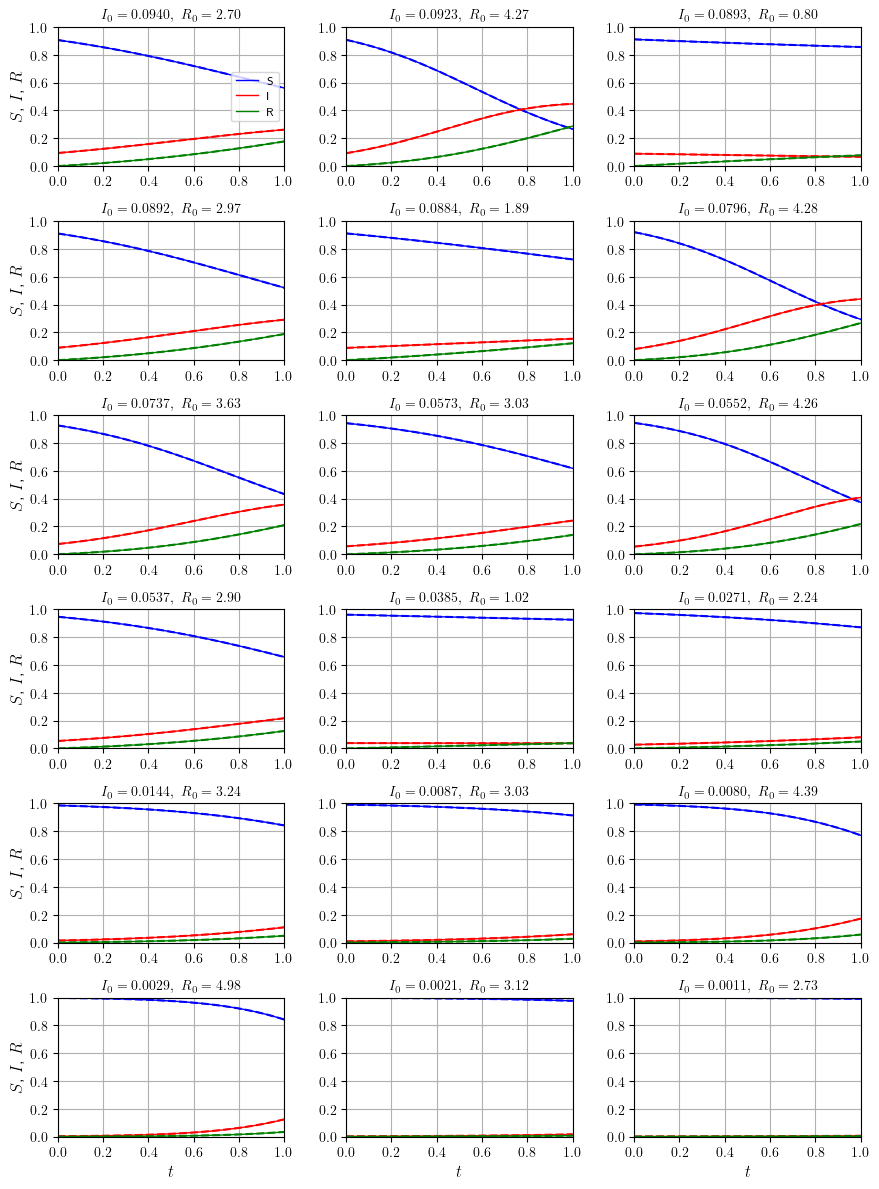

In [19]:
def plot_results(data, 
                 xmin=lower_bounds[0],  xmax=upper_bounds[0],
                 ymin=0, ymax=1,
                 filename='results.png',
                 ftsize=12):

    plt.rcParams.update({'font.size': 10})

    # work out number of columns and number of plots
    ncols = 3
    nrows = len(data) // ncols

    fgsize= (3*ncols, 2*nrows)
    
    # create an empty figure
    fig = plt.figure(figsize=fgsize)

    colors = ['blue', 'red', 'green']
    labels = ['S', 'I', 'R']
    
    for i, (t, approx1, approx2, I0, R_0) in enumerate(data[:nrows*ncols]):

        ax  = fig.add_subplot(nrows, ncols, i+1)
        
        # setup axes
        ax.set_xlim(xmin, xmax)
        ax.set_ylim(ymin, ymax)
        
        if i >= (nrows-1) * ncols:
            ax.set_xlabel(r'$t$', fontsize=ftsize)
        
        if i % ncols == 0:
            ax.set_ylabel(r'$S$, $I$, $R$', fontsize=ftsize)

        # annotate plot
        ax.set_title(r'$I_0 = %6.4f,\ R_0 = %4.2f$' % (I0, R_0), fontsize=10)

        # RK45 (solid) and PINN (dashed)
        for k in range(3):
            ax.plot(t, approx1[k], color=colors[k], linestyle='solid', 
                    linewidth=1.0, label=labels[k] if i == 0 else None)
            ax.plot(t, approx2[k], color=colors[k], linestyle='dashed', 
                    linewidth=1.5)
        if i == 0:
            ax.legend(fontsize=8, loc='center right')
        ax.grid()
        
    fig.tight_layout()
    plt.savefig(filename)

# ------------------------------------------------------------
data = get_data(solution, test_loader, config)
print(len(data))
plot_results(data, filename='results_exercise.png')

## Accuracy
Is a small loss enough to guarantee an accurate solution? The real test is a direct comparison with the numerical solution. For each of $M$ test points $(I_0, R_0)$ we compute the maximum, over $t$ and over $S$, $I$, and $R$, of $|{\rm PINN} - {\rm RK45}|$, and then summarize these $M$ numbers. The worst cases show where in parameter space the PINN struggles.

In [20]:
def accuracy(soln, loader, M=200,
             tmin=lower_bounds[0], tmax=upper_bounds[0], nt=201):

    soln.eval()
    _, p = next(iter(loader))
    p = p[:M].detach()

    t = torch.linspace(tmin, tmax, nt).view(-1, 1).to(p.device)
    T = t.cpu().view(-1).numpy()

    results = []
    for I0, R_0 in p:
        i0, r_0 = I0.item(), R_0.item()
        
        exact = np.array(RK45Solution(1 - i0, i0, r_0)(T, rtol=1e-8, atol=1e-10))
        
        P = torch.cat([I0 * torch.ones_like(t), R_0 * torch.ones_like(t)], dim=1)
        # no torch.no_grad(): forward needs autograd for dg/dt at t = 0
        approx = soln.sir(t, P).detach().cpu().numpy().T
            
        results.append((np.abs(approx - exact).max(), i0, r_0))

    errors = np.array([e for e, _, _ in results])
    print(f'max |PINN - RK45| over {len(errors)} test points')
    print(f'  median: {np.median(errors):9.2e}')
    print(f'  90%:    {np.quantile(errors, 0.9):9.2e}')
    print(f'  worst:  {errors.max():9.2e}')
    print('\nworst cases')
    for e, i0, r_0 in sorted(results, reverse=True)[:5]:
        print(f'  error: {e:8.2e}  I0: {i0:8.2e}  R_0: {r_0:5.2f}')

accuracy(solution, test_loader)

max |PINN - RK45| over 200 test points
  median:  1.58e-05
  90%:     8.44e-05
  worst:   2.27e-04

worst cases
  error: 2.27e-04  I0: 9.77e-02  R_0:  4.69
  error: 1.91e-04  I0: 7.83e-02  R_0:  4.96
  error: 1.89e-04  I0: 9.81e-02  R_0:  4.92
  error: 1.32e-04  I0: 6.07e-02  R_0:  4.94
  error: 1.06e-04  I0: 9.87e-02  R_0:  3.10
